## D2 · Continuous probability

The normal distribution with scipy, joint and conditional probability, and Bayes.

In [1038]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

from scipy.stats import norm

# Flipper lengths (mm) of two penguin species: the Adelie penguin and the Chinstrap penguin
df_complete = df_penguins.dropna()
col_adelie = df_complete.loc[df_complete["species"] == "Adelie", "flipper_length_mm"]
col_chinstrap = df_complete.loc[df_complete["species"] == "Chinstrap", "flipper_length_mm"]

### The normal distribution

#### Probability density

**D2.01**

`norm.pdf(x, mu, sd)`

The `norm.pdf(x, mu, sd)` function allows us to find the height of the bell curve at x. It is useful for drawing the curve and for Bayes calculations. Alternatively, `scipy.stats.norm(mu, sd).pdf(x)` fixes the parameters first. Note that a density is **not** a probability.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the density comes from a normal distribution fitted with the sample mean and standard deviation. It describes the data only if the flipper lengths are approximately normal, which a histogram with a normal curve, or a QQ plot, checks.

In [1039]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1040]:
print(f"density at 190 mm: {norm.pdf(190, mu_a, sd_a):.4f}")

density at 190 mm: 0.0612


In [1041]:
print(f"density at 180 mm: {norm.pdf(180, mu_a, sd_a):.4f}")      # further from the mean, so lower

density at 180 mm: 0.0184


*See also:* Plotting a PDF from a table (D2) · P(X ≤ x) with the CDF (D2) · Comparing a histogram with a normal curve (D2) · QQ plots (D4)

#### P(X ≤ x) with the CDF

**D2.02**

`norm.cdf(x, mu, sd)`

The `norm.cdf(x, mu, sd)` function allows us to find `P(X ≤ x)`, the area under the curve to the left of x. It is useful for "what is the chance of a value below…?" questions. Alternatively, `1 - norm.cdf(...)` or `norm.sf` gives the upper tail.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the probability is correct only if the flipper lengths are approximately normal. The histogram with a normal curve (see the linked example) checks this.

In [1042]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1043]:
print(f"P(flipper <= 185 mm) = {norm.cdf(185, mu_a, sd_a):.4f}")

P(flipper <= 185 mm) = 0.2170


*See also:* Upper tails with `sf` (D2) · P(X > x) (D2) · P(a < X < b) (D2) · Plotting a CDF from a table (D2) · Comparing a histogram with a normal curve (D2)

#### P(X > x)

**D2.03**

`1 - norm.cdf(x, mu, sd)`

Subtracting the CDF from 1 allows us to find `P(X > x)`, the upper tail. It is useful for "what is the chance of exceeding…?" questions. Alternatively, `norm.sf(x, mu, sd)` does the same and is more accurate far into the tail.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the probability is correct only if the flipper lengths are approximately normal (see the linked example).

In [1044]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1045]:
below = norm.cdf(195, mu_a, sd_a)
print(f"P(flipper <= 195 mm) = {below:.4f}")

P(flipper <= 195 mm) = 0.7736


In [1046]:
print(f"P(flipper >  195 mm) = {1 - below:.4f}")

P(flipper >  195 mm) = 0.2264


*See also:* P(X ≤ x) with the CDF (D2) · Upper tails with `sf` (D2) · Comparing a histogram with a normal curve (D2) · The complement rule (D1)

#### P(a < X < b)

**D2.04**

`norm.cdf(b, mu, sd) - norm.cdf(a, mu, sd)`

Subtracting two CDF values allows us to find `P(a < X < b)`. It is useful for the probability of a range of values. Alternatively, count the proportion of data in the range with a mask.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the probability is correct only if the flipper lengths are approximately normal (see the linked example).

In [1047]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1048]:
a, b = 189.5, 190.5
print(f"P({a} < flipper < {b}) = {norm.cdf(b, mu_a, sd_a) - norm.cdf(a, mu_a, sd_a):.4f}")

P(189.5 < flipper < 190.5) = 0.0611


*See also:* P(X ≤ x) with the CDF (D2) · Range probabilities (D1) · Comparing a histogram with a normal curve (D2)

#### Tables of PDF values

**D2.05**

`x = np.arange(start, stop, step); df['pdf'] = norm.pdf(x, mu, sd)`

If we want to draw a curve or combine distributions, then we can evaluate `norm.pdf` over a range of x values and store the (x, y) points in a table. It is useful for plotting and for Bayes calculations. Alternatively, `np.linspace` with `plt.plot` draws a curve without a table.

**Context.** The data are the flipper lengths (mm) of Adelie penguins and Chinstrap penguins, two of the three penguin species in the dataset.

In [1049]:
# mean and standard deviation of the flipper lengths (mm) of each species
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
mu_c, sd_c = col_chinstrap.mean(), col_chinstrap.std()
print(f"Adelie penguins:    mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins:    mean = 190.1 mm, sd = 6.5 mm


In [1050]:
print(f"Chinstrap penguins: mean = {mu_c:.1f} mm, sd = {sd_c:.1f} mm")

Chinstrap penguins: mean = 195.8 mm, sd = 7.1 mm


In [1051]:
df_curve = pd.DataFrame({"flipper": np.arange(160, 230.1, 0.5)})

In [1052]:
# display example dataframe
df_curve

,flipper
0,160.0
1,160.5
2,161.0
3,161.5
4,162.0
...,...
136,228.0
137,228.5
138,229.0
139,229.5


In [1053]:
# display example data
df_curve.head(3)              # before: only the x values

,flipper
0,160.0
1,160.5
2,161.0


In [1054]:
df_curve["pdf_c"] = norm.pdf(df_curve["flipper"], mu_c, sd_c)
df_curve["pdf_a"] = norm.pdf(df_curve["flipper"], mu_a, sd_a)
df_curve["cdf_a"] = norm.cdf(df_curve["flipper"], mu_a, sd_a)
df_curve.iloc[::20]          # after: every 20th row of the finished table

,flipper,pdf_c,pdf_a,cdf_a
0,160.0,1.857624e-07,1.446444e-06,0.000002
20,170.0,7.957601e-05,5.289457e-04,0.001027
40,180.0,4.772768e-03,1.842778e-02,0.060683
60,190.0,4.007950e-02,6.116276e-02,0.493716
80,200.0,4.712358e-02,1.933986e-02,0.935437
100,210.0,7.757433e-03,5.826020e-04,0.998859
120,220.0,1.787976e-04,1.672025e-06,0.999998
140,230.0,5.769914e-07,4.571576e-10,1.000000


*See also:* Creating evenly spaced points with `np.linspace` (A4) · Probability density (D2) · Creating a sequence with `np.arange` (A4) · Plotting a PDF from a table (D2)

#### Plotting a PDF from a table

**D2.06**

`sns.lineplot(data=df, x='col_1', y='col_2', label=text)`

If we have a set of data points giving the x and y coordinates of a probability density function (a PDF), then we can plot them as a line using `sns.lineplot`. It is useful for comparing two distributions on one set of axes. Alternatively, `plt.plot(x, norm.pdf(x, mu, sd))` draws the curve without a DataFrame.

**Context.** The data are the flipper lengths (mm) of Adelie penguins and Chinstrap penguins, two of the three penguin species in the dataset.

In [1055]:
# mean and standard deviation of the flipper lengths (mm) of each species
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
mu_c, sd_c = col_chinstrap.mean(), col_chinstrap.std()
print(f"Adelie penguins:    mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins:    mean = 190.1 mm, sd = 6.5 mm


In [1056]:
print(f"Chinstrap penguins: mean = {mu_c:.1f} mm, sd = {sd_c:.1f} mm")

Chinstrap penguins: mean = 195.8 mm, sd = 7.1 mm


In [1057]:
df_curve = pd.DataFrame({"flipper": np.arange(160, 230.1, 0.5)})

In [1058]:
# display example dataframe
df_curve

,flipper
0,160.0
1,160.5
2,161.0
3,161.5
4,162.0
...,...
136,228.0
137,228.5
138,229.0
139,229.5


In [1059]:
df_curve["pdf_c"] = norm.pdf(df_curve["flipper"], mu_c, sd_c)
df_curve["pdf_a"] = norm.pdf(df_curve["flipper"], mu_a, sd_a)
df_curve.head(3)

,flipper,pdf_c,pdf_a
0,160.0,1.857624e-07,0.000001
1,160.5,2.635286e-07,0.000002
2,161.0,3.720171e-07,0.000003


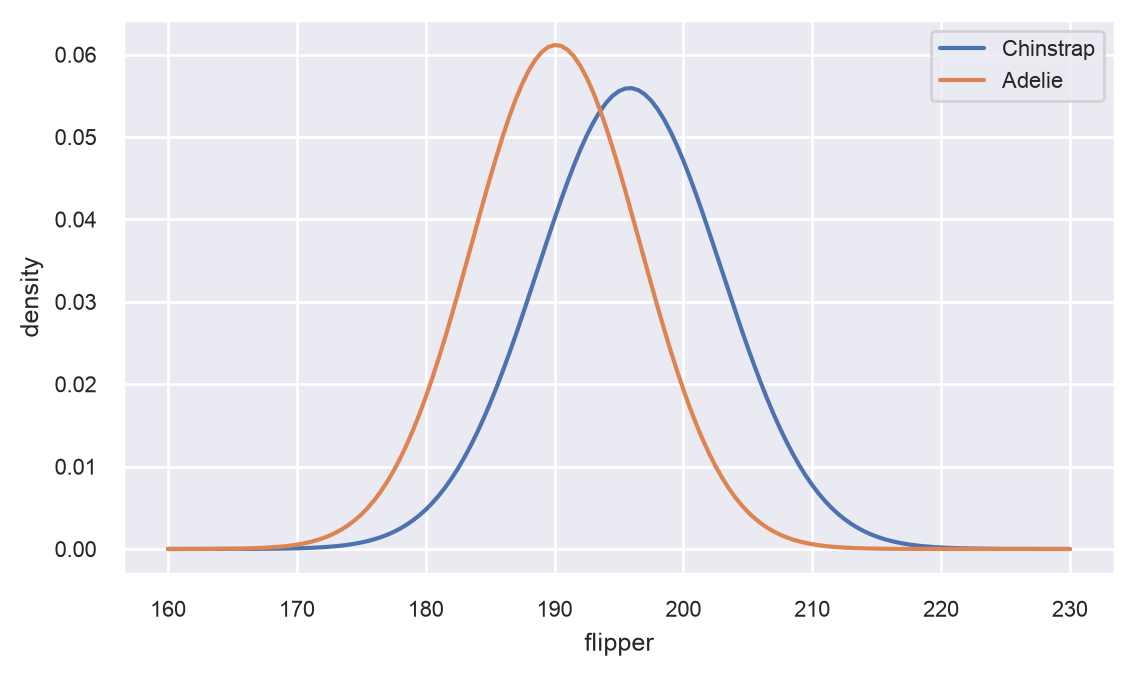

In [1060]:
sns.lineplot(data=df_curve, x="flipper", y="pdf_c", label="Chinstrap")
sns.lineplot(data=df_curve, x="flipper", y="pdf_a", label="Adelie")
plt.ylabel("density");

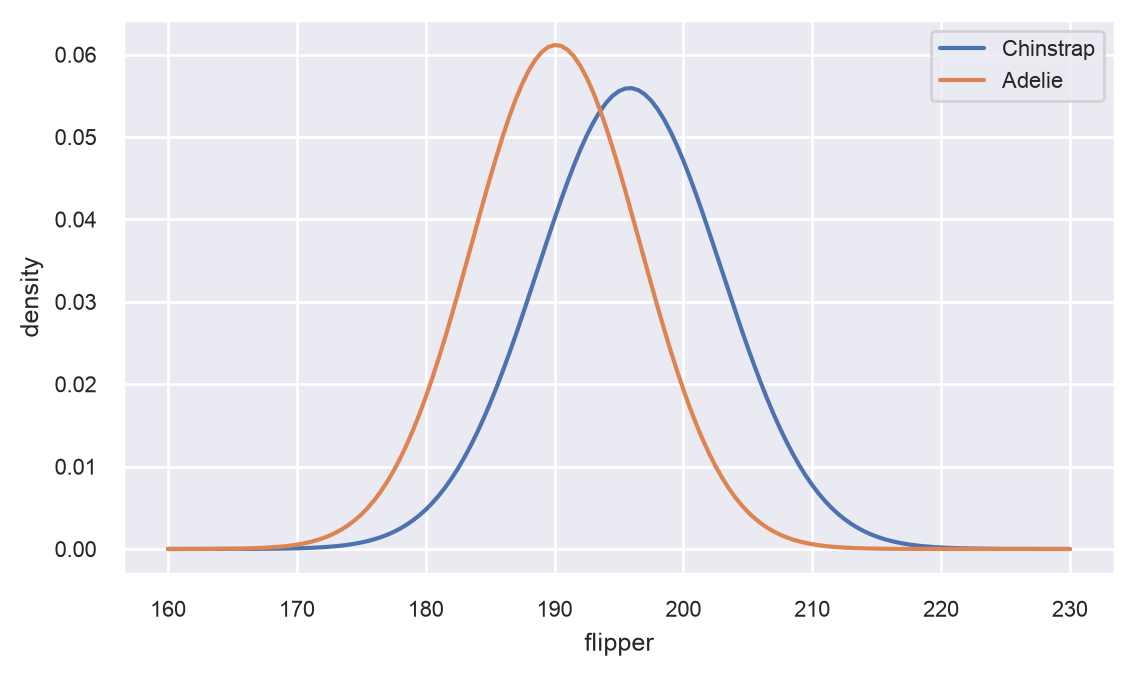

In [1061]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
sns.lineplot(data=df_curve, x="flipper", y="pdf_c", label="Chinstrap", ax=ax)
sns.lineplot(data=df_curve, x="flipper", y="pdf_a", label="Adelie", ax=ax)
ax.set_ylabel("density");

*See also:* Probability density (D2) · Tables of PDF values (D2) · Overlaying lines on one axis (C3)

#### Plotting a CDF from a table

**D2.07**

`sns.lineplot(data=df, x='x', y='cdf')`

If we have a set of data points giving the x and y coordinates of a cumulative distribution function (a CDF), then we can plot them as a line using `sns.lineplot`. It is useful for reading percentiles off a plot. Alternatively, `sns.ecdfplot` draws an empirical CDF from raw data.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

In [1062]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1063]:
df_curve = pd.DataFrame({"flipper": np.arange(160, 230.1, 0.5)})

In [1064]:
# display example dataframe
df_curve

,flipper
0,160.0
1,160.5
2,161.0
3,161.5
4,162.0
...,...
136,228.0
137,228.5
138,229.0
139,229.5


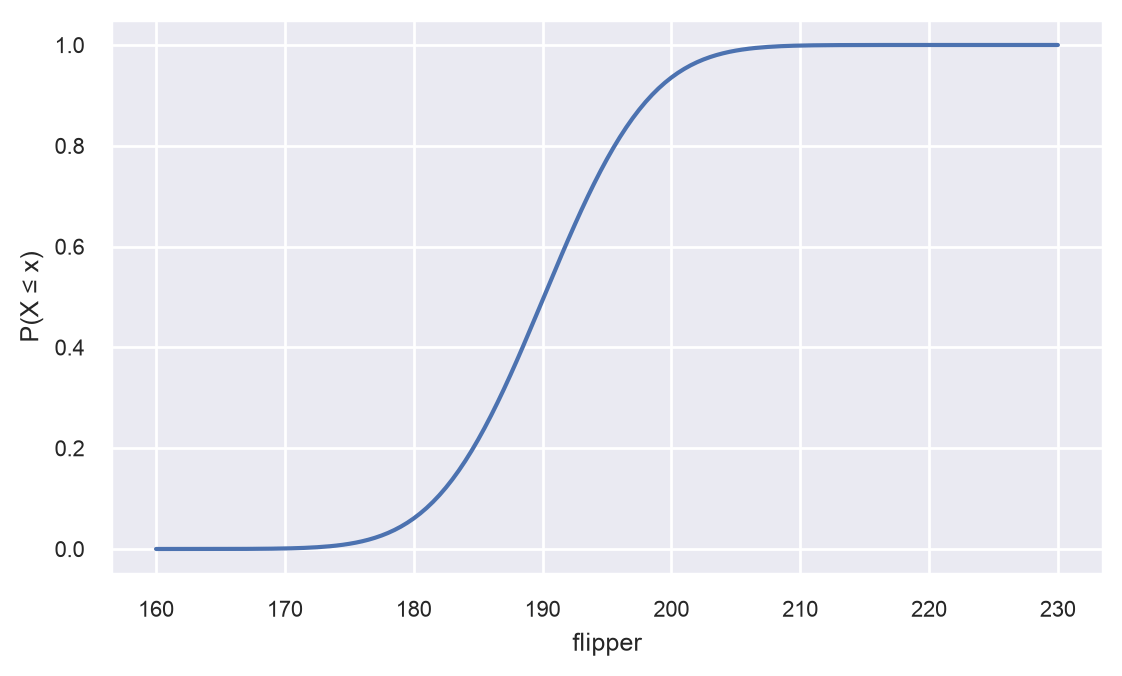

In [1065]:
df_curve["cdf_a"] = norm.cdf(df_curve["flipper"], mu_a, sd_a)
sns.lineplot(data=df_curve, x="flipper", y="cdf_a")
plt.ylabel("P(X ≤ x)");

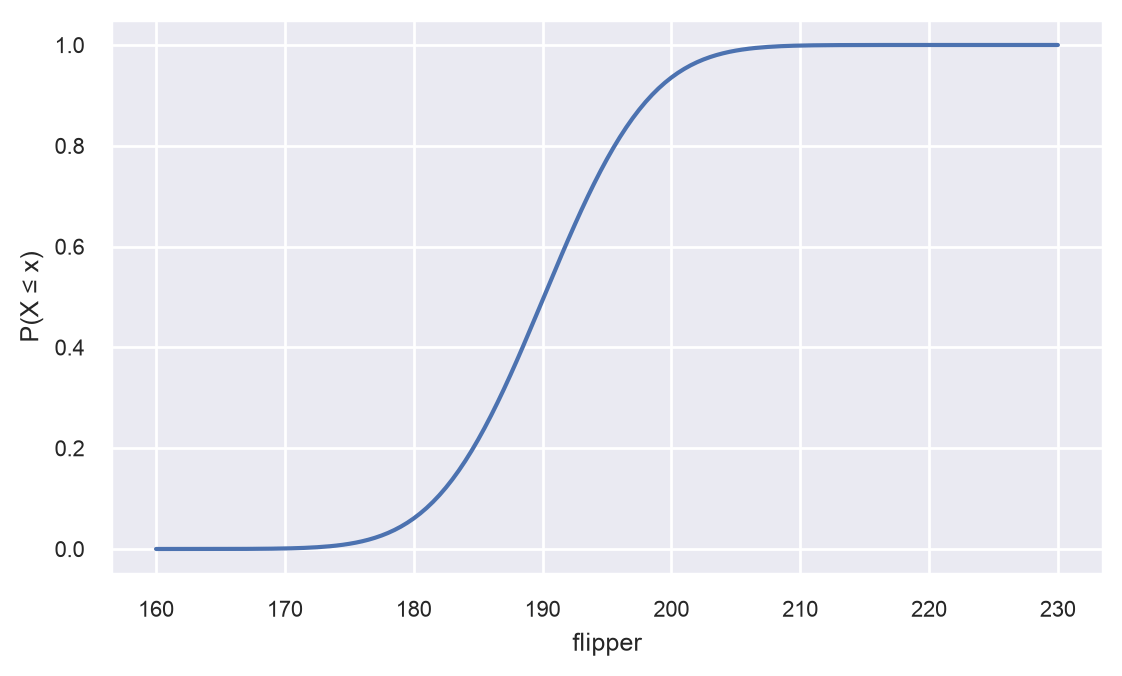

In [1066]:
# the same plot in object-oriented style (ax. methods)
df_curve["cdf_a"] = norm.cdf(df_curve["flipper"], mu_a, sd_a)
fig, ax = plt.subplots()
sns.lineplot(data=df_curve, x="flipper", y="cdf_a", ax=ax)
ax.set_ylabel("P(X ≤ x)");

*See also:* P(X ≤ x) with the CDF (D2) · Drawing a cumulative distribution with `ecdfplot` (C3) · Plotting a PDF from a table (D2)

#### Upper tails with `sf`

**D2.08**

`norm.sf(x, mu, sd)`

***(non-examinable)***

The `norm.sf()` ("survival function") allows us to find `P(X > x)` directly. It is useful for very small upper-tail probabilities, where `1 - cdf` loses accuracy. Alternatively, `1 - norm.cdf(x, mu, sd)` is fine for everyday values.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the normal model must describe the upper tail well. Very small tail probabilities, such as those shown here, depend on the tail of the model and are rarely supported by the data.

In [1067]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1068]:
print(f"sf         : {norm.sf(195, mu_a, sd_a)}")

sf         : 0.22635540521585662


In [1069]:
print(f"1 - cdf    : {1 - norm.cdf(195, mu_a, sd_a)}")

1 - cdf    : 0.22635540521585662


In [1070]:
print(f"far tail sf: {norm.sf(10)}    1 - cdf: {1 - norm.cdf(10)}")

far tail sf: 7.619853024160474e-24    1 - cdf: 0.0


*See also:* P(X > x) (D2) · Probability density (D2) · Comparing a histogram with a normal curve (D2)

#### Percentiles with `ppf`

**D2.09**

`norm.ppf(q, mu, sd)`

***(non-examinable)***

The `norm.ppf(q, mu, sd)` function allows us to find the value below which a fraction q of the distribution lies. It is useful for critical values and percentiles. Alternatively, `np.percentile` finds percentiles of data rather than of a model.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the percentile is a property of the fitted normal model. It matches the percentile of the data only if the data are approximately normal.

In [1071]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1072]:
print(f"95th percentile of Adelie flipper length: {norm.ppf(0.95, mu_a, sd_a):.1f} mm")

95th percentile of Adelie flipper length: 200.8 mm


In [1073]:
print(f"97.5th percentile of N(0, 1): {norm.ppf(0.975):.3f}")

97.5th percentile of N(0, 1): 1.960


*See also:* Finding the median and percentiles (A4) · P(X ≤ x) with the CDF (D2) · Confidence intervals (D4) · Comparing a histogram with a normal curve (D2)

#### Z-scores

**D2.10**

`z = (x - mu) / sd; norm.cdf(z)`

***(non-examinable)***

If we have a value and the mean and standard deviation of its distribution, then the z-score `(x − μ) / σ` says how many standard deviations the value lies from the mean. It is useful for comparing values from different distributions. Alternatively, `norm.cdf(x, mu, sd)` gives the same probability without converting.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the probability found from a z-score assumes an approximately normal distribution. For other shapes the z-score still measures the distance from the mean in standard deviations, but the probability does not apply.

In [1074]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1075]:
z = (180 - mu_a) / sd_a
print(f"z = {z:.2f}")

z = -1.55


In [1076]:
print(f"P(Z <= z) = {norm.cdf(z):.4f}   same as {norm.cdf(180, mu_a, sd_a):.4f}")

P(Z <= z) = 0.0607   same as 0.0607


In [1077]:
print(f"A flipper length of 180 mm is {abs(z):.2f} standard deviations {'below' if z < 0 else 'above'} the Adelie mean, and {norm.cdf(z):.1%} of Adelie penguins are expected to have a flipper this length or shorter.")

A flipper length of 180 mm is 1.55 standard deviations below the Adelie mean, and 6.1% of Adelie penguins are expected to have a flipper this length or shorter.


*See also:* P(X ≤ x) with the CDF (D2) · Probability density (D2) · Comparing a histogram with a normal curve (D2) · Percentiles with `ppf` (D2)

#### Random samples with `rvs`

**D2.11**

`norm.rvs(mu, sd, size=n)`

***(non-examinable)***

The `norm.rvs(mu, sd, size=n)` function allows us to draw random values from a normal distribution. It is useful for simulation. Alternatively, `np.random.normal(mu, sd, n)` does the same.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the simulated values come from the fitted normal model, so they resemble the real data only as far as the normal model fits.

In [1078]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1079]:
np.random.seed(1)                          # fixed seed, so the output is repeatable

In [1080]:
sample = norm.rvs(mu_a, sd_a, size=5)
sample.round(0)

array([201., 186., 187., 183., 196.])

*See also:* Drawing normal random numbers (A4) · Probability density (D2) · The 68-95-99.7 rule (D2) · Comparing a histogram with a normal curve (D2)

#### The 68-95-99.7 rule

**D2.12**

`norm.cdf(k) - norm.cdf(-k)`

***(non-examinable)***

If a distribution is normal, then about 68% of it lies within 1 standard deviation of the mean (the 1-sigma rule), about 95% within 2 and about 99.7% within 3. It is useful for quick sanity checks and for spotting unusual values. Alternatively, count the proportion of the data within each range.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

Assumption: the percentages hold exactly only for a normal distribution. Skewed data, or data with long tails, give different proportions.
The bands show the proportion within 1, 2 and 3 standard deviations of the mean (sigma is the standard deviation).

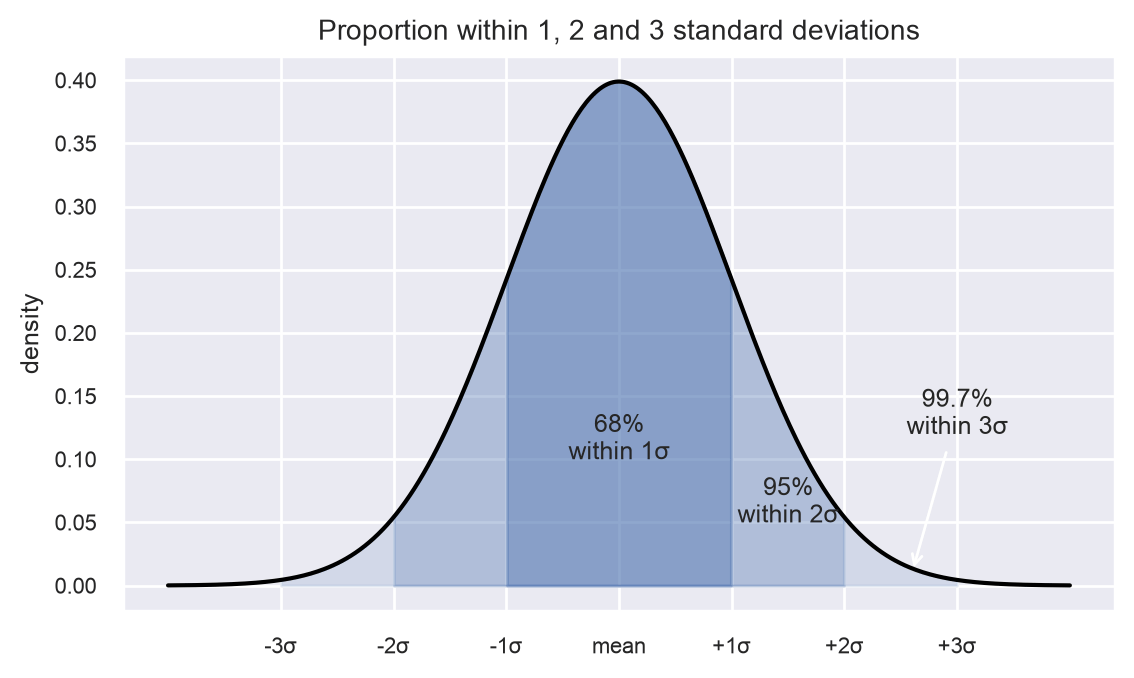

In [1081]:
x = np.linspace(-4, 4, 400)
y = norm.pdf(x)
plt.plot(x, y, color="black")
for k, shade in ((3, 0.15), (2, 0.25), (1, 0.4)):
    plt.fill_between(x, y, where=abs(x) <= k, alpha=shade, color="C0")
plt.text(0, 0.1, "68%\nwithin 1σ", ha="center")
plt.text(1.5, 0.05, "95%\nwithin 2σ", ha="center")
plt.annotate("99.7%\nwithin 3σ", (2.6, 0.01), (3.0, 0.12), ha="center", arrowprops={"arrowstyle": "->"})
plt.xticks(range(-3, 4), ["-3σ", "-2σ", "-1σ", "mean", "+1σ", "+2σ", "+3σ"])
plt.title("Proportion within 1, 2 and 3 standard deviations")
plt.ylabel("density");

The exact proportions for a normal distribution come from the CDF:

In [1082]:
for k in (1, 2, 3):
    print(f"within {k} sd: {norm.cdf(k) - norm.cdf(-k):.4f}")

within 1 sd: 0.6827
within 2 sd: 0.9545
within 3 sd: 0.9973


The same check on data: the proportion of Adelie penguin flipper lengths within each range of the mean (these are estimates from a sample, so they differ slightly from the rule).

In [1083]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1084]:
for k in (1, 2, 3):
    mask_within = (col_adelie - mu_a).abs() <= k * sd_a
    print(f"within {k} sd: {mask_within.mean():.3f}")

within 1 sd: 0.712
within 2 sd: 0.959
within 3 sd: 0.993


In [1085]:
props = [((col_adelie - mu_a).abs() <= k * sd_a).mean() for k in (1, 2, 3)]
exact = [norm.cdf(k) - norm.cdf(-k) for k in (1, 2, 3)]
print("The proportions for the Adelie penguin flipper lengths (" + ", ".join(f"{p:.3f}" for p in props)
      + ") are compared with the normal-distribution values (" + ", ".join(f"{p:.3f}" for p in exact)
      + "). The largest difference is " + f"{max(abs(a - b) for a, b in zip(props, exact)):.3f}" + ", so the 68-95-99.7 rule describes these data well.")

The proportions for the Adelie penguin flipper lengths (0.712, 0.959, 0.993) are compared with the normal-distribution values (0.683, 0.954, 0.997). The largest difference is 0.030, so the 68-95-99.7 rule describes these data well.


*See also:* P(a < X < b) (D2) · Probability density (D2) · Z-scores (D2) · Percentiles with `ppf` (D2)

#### Comparing a histogram with a normal curve

**D2.13**

`plt.hist(data, density=True); plt.plot(x, norm.pdf(x, mu, sd))`

***(non-examinable)***

If we have data and a fitted normal distribution, then drawing a density-scaled histogram with the normal curve on top allows us to judge whether the data look normal. It is useful before using methods that assume normality. Alternatively, a QQ plot is a sharper check.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

In [1086]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


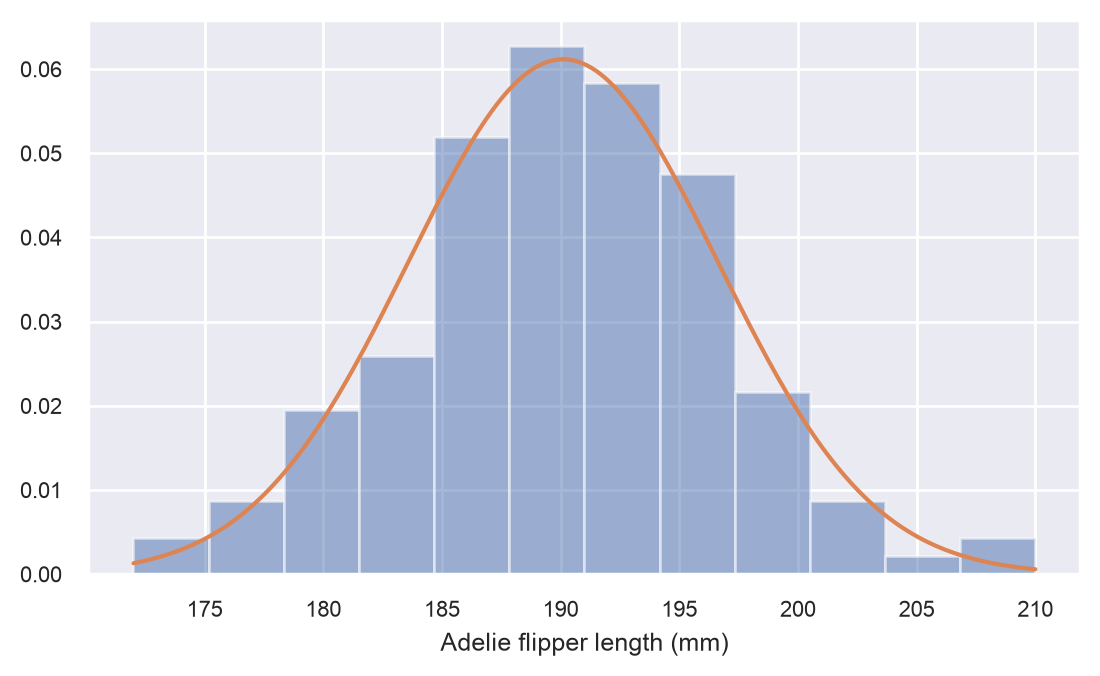

In [1087]:
col_data = col_adelie
xs = np.linspace(col_data.min(), col_data.max(), 200)
plt.hist(col_data, bins=12, density=True, alpha=0.5)
plt.plot(xs, norm.pdf(xs, mu_a, sd_a))
plt.xlabel("Adelie flipper length (mm)");

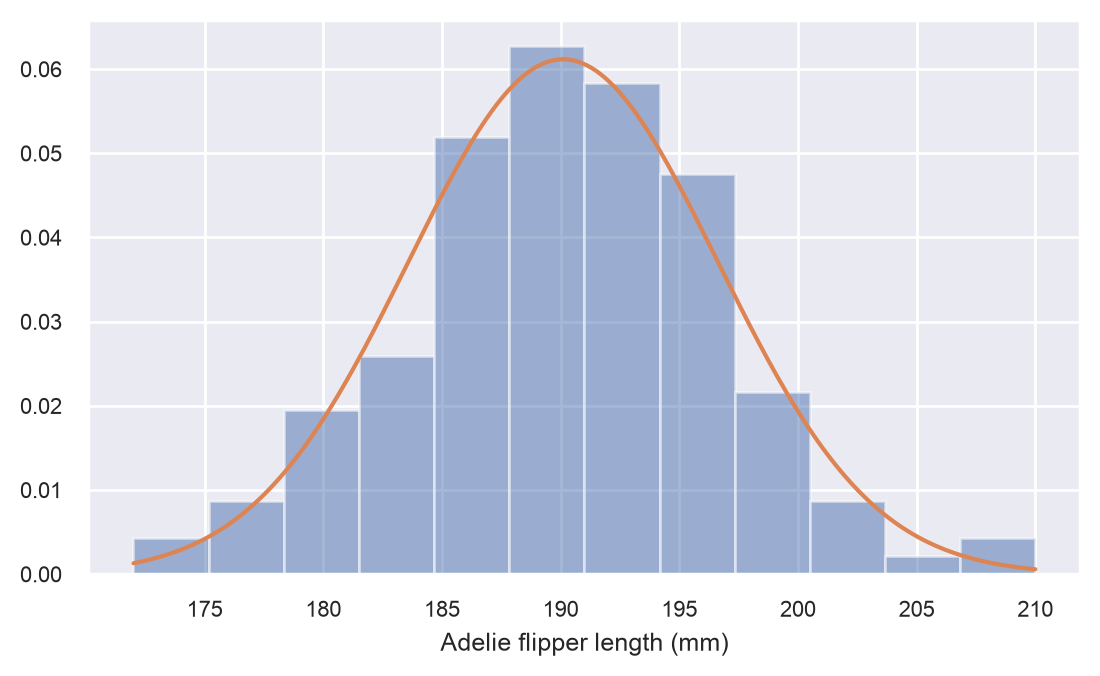

In [1088]:
# the same plot in object-oriented style (ax. methods)
col_data = col_adelie
xs = np.linspace(col_data.min(), col_data.max(), 200)
fig, ax = plt.subplots()
ax.hist(col_data, bins=12, density=True, alpha=0.5)
ax.plot(xs, norm.pdf(xs, mu_a, sd_a))
ax.set_xlabel("Adelie flipper length (mm)");

In [1089]:
skew = col_data.skew()
f'The skewness of the flipper lengths is {skew:.2f} (0 for a symmetric distribution), so the histogram is ' + ('close to symmetric, as the normal curve is.' if abs(skew) < 0.5 else 'noticeably skewed, which the normal curve does not capture.')

'The skewness of the flipper lengths is 0.08 (0 for a symmetric distribution), so the histogram is close to symmetric, as the normal curve is.'

*See also:* Scaling a histogram as a density (C2) · QQ plots (D4)

#### Shading a tail of a distribution

**D2.14**

`plt.fill_between(x, norm.pdf(x, mu, sd), where=x < limit)`

***(non-examinable)***

If we have a curve and a cut-off, then `fill_between` with a `where=` condition shades the region that represents a probability. It is useful for showing what a p-value is. Alternatively, `plt.axvline` marks the cut-off only.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

In [1090]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


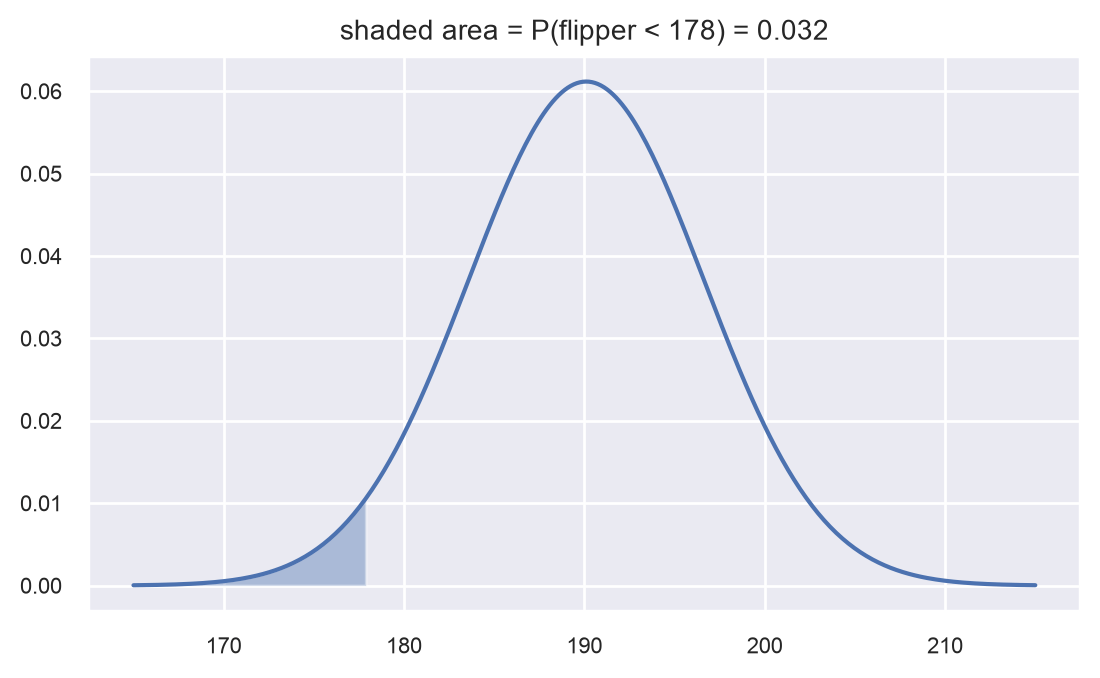

In [1091]:
xs = np.linspace(165, 215, 300)
plt.plot(xs, norm.pdf(xs, mu_a, sd_a))
plt.fill_between(xs, norm.pdf(xs, mu_a, sd_a), where=xs < 178, alpha=0.4)
plt.title(f"shaded area = P(flipper < 178) = {norm.cdf(178, mu_a, sd_a):.3f}");

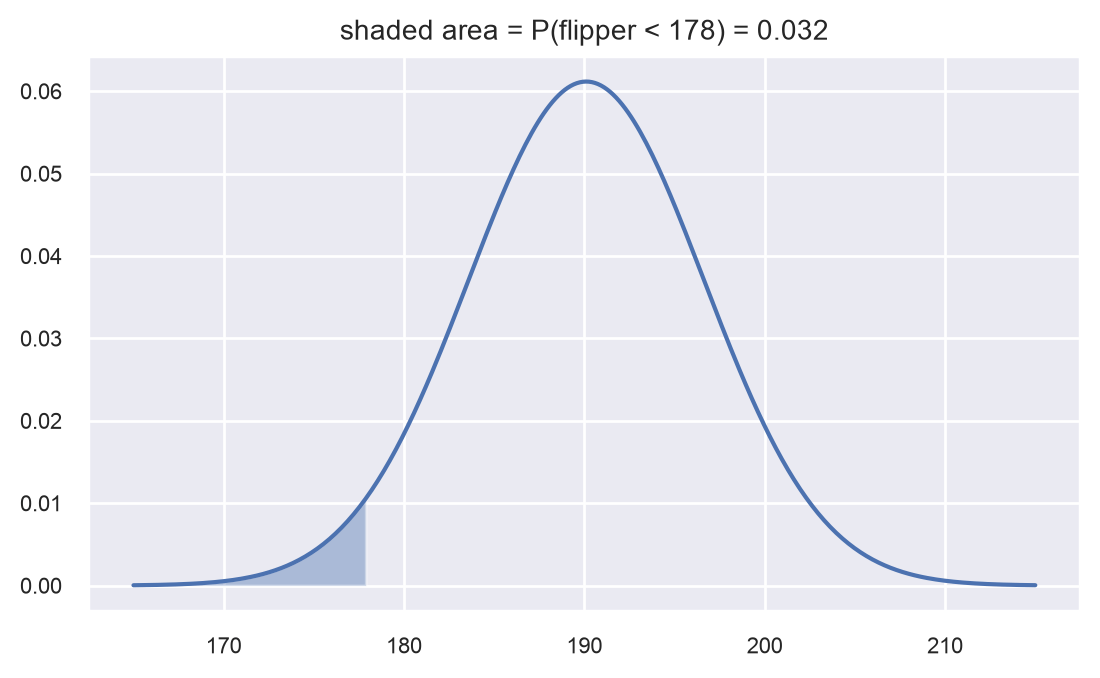

In [1092]:
# the same plot in object-oriented style (ax. methods)
xs = np.linspace(165, 215, 300)
fig, ax = plt.subplots()
ax.plot(xs, norm.pdf(xs, mu_a, sd_a))
ax.fill_between(xs, norm.pdf(xs, mu_a, sd_a), where=xs < 178, alpha=0.4)
ax.set_title(f"shaded area = P(flipper < 178) = {norm.cdf(178, mu_a, sd_a):.3f}");

*See also:* Drawing a vertical line (C1) · Shading an area (C2) · One-tailed p-values (D3) · Other distributions (D2)

#### Other distributions

**D2.15**

`stats.uniform, stats.expon, stats.t`

***(non-examinable)***

The classes `stats.uniform`, `stats.expon` and `stats.t` allow us to use other distributions with the same `.pdf/.cdf/.ppf` methods. They are useful when data are not normal, and `stats.t` is used in t-tests. Alternatively, `np.random` can draw from them but has no `cdf`.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. A normal distribution is fitted using their mean and standard deviation.

In [1093]:
print(f"expon  P(X <= 1), scale 2: {stats.expon.cdf(1, scale=2):.4f}")

expon  P(X <= 1), scale 2: 0.3935


In [1094]:
print(f"t      P(T <= 2), df 10   : {stats.t.cdf(2, df=10):.4f}")

t      P(T <= 2), df 10   : 0.9633


*See also:* P(X ≤ x) with the CDF (D2) · Critical t values (D4) · Random samples with `rvs` (D2)

### Joint, conditional and Bayes

#### The total probability rule

**D2.16**

`f(flipper) = f(flipper | A)·P(A) + f(flipper | C)·P(C)`

If we know how common each group is and the density within each group, then weighting each group's density by its share gives the overall density, `f(flipper) = f(flipper | Adelie)P(Adelie) + f(flipper | Chinstrap)P(Chinstrap)`, where f marks a density because flipper length is continuous. It is useful as the denominator in Bayes' theorem. Alternatively, with data, count the proportion of all penguins in each flipper-length range.

**Context.** The data are the flipper lengths (mm) of Adelie penguins and Chinstrap penguins, two of the three penguin species in the dataset.

Assumptions: within each species the flipper lengths are approximately normal; the two species are present in the stated proportions (half each here); and every penguin belongs to one of the two species.
Assume half of the penguins are Adelie and half are Chinstrap.

In [1095]:
# mean and standard deviation of the flipper lengths (mm) of each species
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
mu_c, sd_c = col_chinstrap.mean(), col_chinstrap.std()
print(f"Adelie penguins:    mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins:    mean = 190.1 mm, sd = 6.5 mm


In [1096]:
print(f"Chinstrap penguins: mean = {mu_c:.1f} mm, sd = {sd_c:.1f} mm")

Chinstrap penguins: mean = 195.8 mm, sd = 7.1 mm


In [1097]:
df_curve = pd.DataFrame({"flipper": np.arange(160, 230.1, 0.5)})

In [1098]:
# display example dataframe
df_curve

,flipper
0,160.0
1,160.5
2,161.0
3,161.5
4,162.0
...,...
136,228.0
137,228.5
138,229.0
139,229.5


In [1099]:
df_curve["pdf_c"] = norm.pdf(df_curve["flipper"], mu_c, sd_c)
df_curve["pdf_a"] = norm.pdf(df_curve["flipper"], mu_a, sd_a)
df_curve.iloc[::20]

,flipper,pdf_c,pdf_a
0,160.0,1.857624e-07,1.446444e-06
20,170.0,7.957601e-05,5.289457e-04
40,180.0,4.772768e-03,1.842778e-02
60,190.0,4.007950e-02,6.116276e-02
80,200.0,4.712358e-02,1.933986e-02
100,210.0,7.757433e-03,5.826020e-04
120,220.0,1.787976e-04,1.672025e-06
140,230.0,5.769914e-07,4.571576e-10


In [1100]:
df_curve["prob_total"] = 0.5 * df_curve["pdf_c"] + 0.5 * df_curve["pdf_a"]
df_curve.iloc[::20]

,flipper,pdf_c,pdf_a,prob_total
0,160.0,1.857624e-07,1.446444e-06,8.161031e-07
20,170.0,7.957601e-05,5.289457e-04,3.042609e-04
40,180.0,4.772768e-03,1.842778e-02,1.160027e-02
60,190.0,4.007950e-02,6.116276e-02,5.062113e-02
80,200.0,4.712358e-02,1.933986e-02,3.323172e-02
100,210.0,7.757433e-03,5.826020e-04,4.170018e-03
120,220.0,1.787976e-04,1.672025e-06,9.023482e-05
140,230.0,5.769914e-07,4.571576e-10,2.887243e-07


In [1101]:
mid = df_curve.loc[(df_curve["flipper"] - (mu_a + mu_c) / 2).abs().idxmin()]
print(f"At a flipper length of {mid['flipper']:.0f} mm, halfway between the two species means, the Adelie density is {mid['pdf_a']:.4f}, the Chinstrap density is {mid['pdf_c']:.4f} and the total density (half of each) is {mid['prob_total']:.4f}.")

At a flipper length of 193 mm, halfway between the two species means, the Adelie density is 0.0554, the Chinstrap density is 0.0517 and the total density (half of each) is 0.0536.


*See also:* Bayes' theorem (D2) · Favourable outcomes over total outcomes (D1) · Comparing a histogram with a normal curve (D2) · Counting combined events (D1)

#### Bayes' theorem

**D2.17**

`P(A | flipper) = f(flipper | A) · P(A) / f(flipper)`

If we know the density `f(flipper | Adelie)`, then Bayes' theorem turns it into `P(Adelie | flipper)`, answering "given this flipper length, how likely is the penguin to be an Adelie?". It is useful for classification and updating beliefs. Alternatively, with data, count how many penguins of a given flipper length are Adelie.

**Context.** The data are the flipper lengths (mm) of Adelie penguins and Chinstrap penguins, two of the three penguin species in the dataset.

Assumptions: as in the total probability rule: normal flipper lengths within each species, equal proportions of the two species (changing them changes the result), and only these two species.

In [1102]:
# mean and standard deviation of the flipper lengths (mm) of each species
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
mu_c, sd_c = col_chinstrap.mean(), col_chinstrap.std()
print(f"Adelie penguins:    mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins:    mean = 190.1 mm, sd = 6.5 mm


In [1103]:
print(f"Chinstrap penguins: mean = {mu_c:.1f} mm, sd = {sd_c:.1f} mm")

Chinstrap penguins: mean = 195.8 mm, sd = 7.1 mm


In [1104]:
df_curve = pd.DataFrame({"flipper": np.arange(160, 230.1, 0.5)})

In [1105]:
# display example dataframe
df_curve

,flipper
0,160.0
1,160.5
2,161.0
3,161.5
4,162.0
...,...
136,228.0
137,228.5
138,229.0
139,229.5


In [1106]:
df_curve["pdf_c"] = norm.pdf(df_curve["flipper"], mu_c, sd_c)
df_curve["pdf_a"] = norm.pdf(df_curve["flipper"], mu_a, sd_a)
df_curve["prob_total"] = 0.5 * df_curve["pdf_c"] + 0.5 * df_curve["pdf_a"]
df_curve.iloc[::20]

,flipper,pdf_c,pdf_a,prob_total
0,160.0,1.857624e-07,1.446444e-06,8.161031e-07
20,170.0,7.957601e-05,5.289457e-04,3.042609e-04
40,180.0,4.772768e-03,1.842778e-02,1.160027e-02
60,190.0,4.007950e-02,6.116276e-02,5.062113e-02
80,200.0,4.712358e-02,1.933986e-02,3.323172e-02
100,210.0,7.757433e-03,5.826020e-04,4.170018e-03
120,220.0,1.787976e-04,1.672025e-06,9.023482e-05
140,230.0,5.769914e-07,4.571576e-10,2.887243e-07


In [1107]:
df_curve["prob_c_given_flipper"] = 0.5 * df_curve["pdf_c"] / df_curve["prob_total"]
df_curve[["flipper", "prob_c_given_flipper"]].iloc[::20].round(3)

,flipper,prob_c_given_flipper
0,160.0,0.114
20,170.0,0.131
40,180.0,0.206
60,190.0,0.396
80,200.0,0.709
100,210.0,0.930
120,220.0,0.991
140,230.0,0.999


In [1108]:
x_c = df_curve.loc[df_curve["prob_c_given_flipper"] >= 0.5, "flipper"].min()
print(f"With equal numbers of both species, a penguin is more likely to be a Chinstrap than an Adelie once its flipper is longer than about {x_c:.0f} mm.")

With equal numbers of both species, a penguin is more likely to be a Chinstrap than an Adelie once its flipper is longer than about 194 mm.


*See also:* The total probability rule (D2) · Plotting a posterior probability curve (D2) · Building a frequency table (D1) · Counting combined events (D1)

#### Plotting a posterior probability curve

**D2.18**

`sns.lineplot(data=df, x='flipper', y='prob_c_given_flipper')`

If we have calculated `P(Chinstrap | flipper)` for a range of flipper lengths, then a line plot shows how the evidence changes with the measurement. It is useful for seeing where a classifier switches from "probably Adelie" to "probably Chinstrap". Alternatively, tabulate the values at chosen flipper lengths.

**Context.** The data are the flipper lengths (mm) of Adelie penguins and Chinstrap penguins, two of the three penguin species in the dataset.

Assumptions: the curve depends on the normal model for each species and on the equal proportions chosen; with other proportions the crossing point moves.

In [1109]:
# mean and standard deviation of the flipper lengths (mm) of each species
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
mu_c, sd_c = col_chinstrap.mean(), col_chinstrap.std()
print(f"Adelie penguins:    mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins:    mean = 190.1 mm, sd = 6.5 mm


In [1110]:
print(f"Chinstrap penguins: mean = {mu_c:.1f} mm, sd = {sd_c:.1f} mm")

Chinstrap penguins: mean = 195.8 mm, sd = 7.1 mm


In [1111]:
df_curve = pd.DataFrame({"flipper": np.arange(160, 230.1, 0.5)})

In [1112]:
# display example dataframe
df_curve

,flipper
0,160.0
1,160.5
2,161.0
3,161.5
4,162.0
...,...
136,228.0
137,228.5
138,229.0
139,229.5


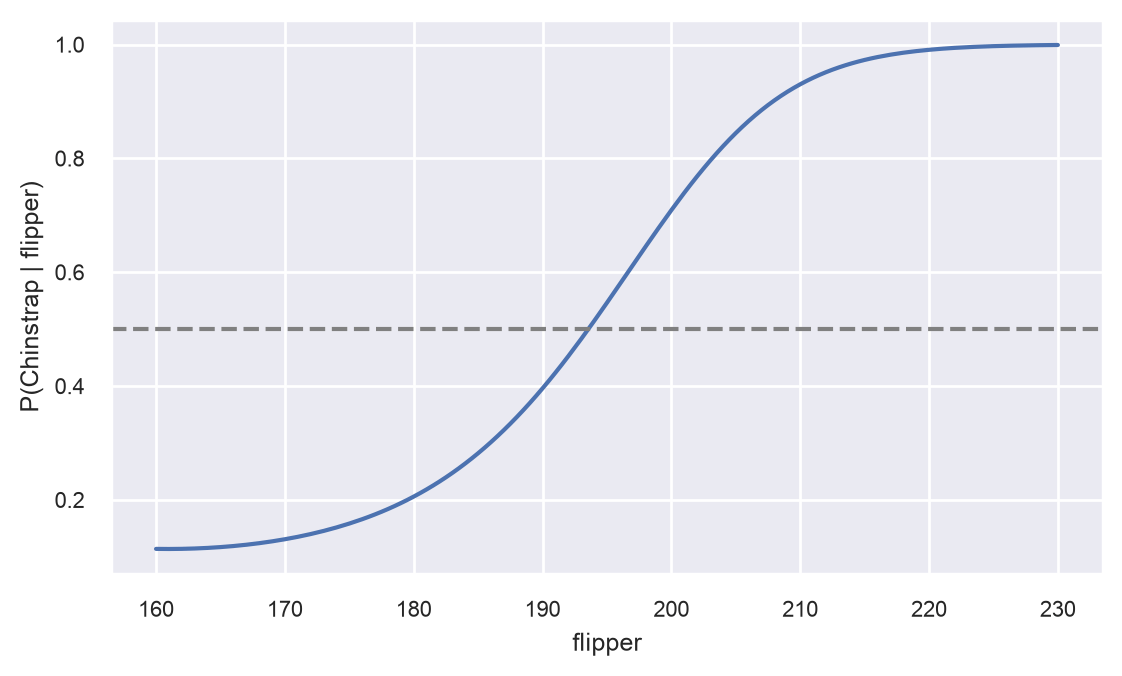

In [1113]:
df_curve["pdf_c"] = norm.pdf(df_curve["flipper"], mu_c, sd_c)
df_curve["pdf_a"] = norm.pdf(df_curve["flipper"], mu_a, sd_a)
df_curve["prob_c_given_flipper"] = 0.5 * df_curve["pdf_c"] / (0.5 * df_curve["pdf_c"] + 0.5 * df_curve["pdf_a"])

sns.lineplot(data=df_curve, x="flipper", y="prob_c_given_flipper")
plt.axhline(0.5, color="grey", linestyle="--")
plt.ylabel("P(Chinstrap | flipper)");

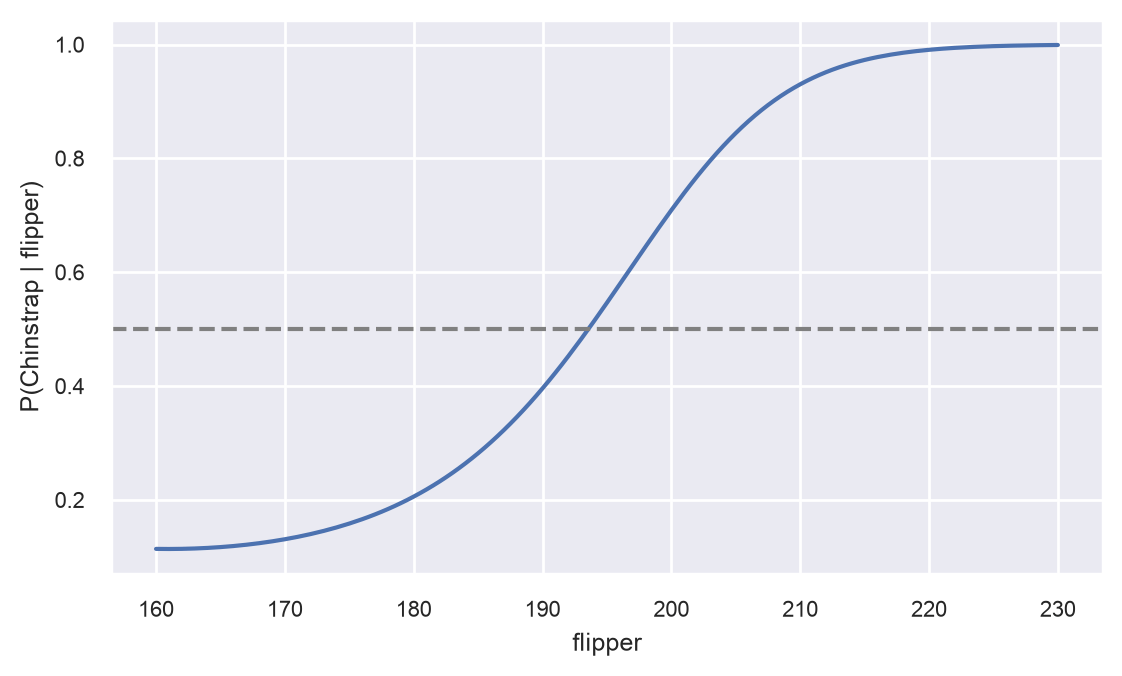

In [1114]:
# the same plot in object-oriented style (ax. methods)
df_curve["pdf_c"] = norm.pdf(df_curve["flipper"], mu_c, sd_c)
df_curve["pdf_a"] = norm.pdf(df_curve["flipper"], mu_a, sd_a)
df_curve["prob_c_given_flipper"] = 0.5 * df_curve["pdf_c"] / (0.5 * df_curve["pdf_c"] + 0.5 * df_curve["pdf_a"])

fig, ax = plt.subplots()
sns.lineplot(data=df_curve, x="flipper", y="prob_c_given_flipper", ax=ax)
ax.axhline(0.5, color="grey", linestyle="--")
ax.set_ylabel("P(Chinstrap | flipper)");

In [1115]:
x_c = df_curve.loc[df_curve["prob_c_given_flipper"] >= 0.5, "flipper"].min()
print(f"The curve crosses 0.5 at a flipper length of about {x_c:.0f} mm: below it a penguin is probably an Adelie, above it probably a Chinstrap.")

The curve crosses 0.5 at a flipper length of about 194 mm: below it a penguin is probably an Adelie, above it probably a Chinstrap.


*See also:* Bayes' theorem (D2) · The total probability rule (D2) · Drawing a line plot (C3)